In [1]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
import pandas as pd
from pathlib import Path

In [2]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return f"{hours}h {minutes:02d}m"


def plot_eddies(ax, eddies, color, crs):

    ms = eddies["maxspeed"]
    oc = eddies["outcontour"]
    cent = eddies["centers"]

    for i in range(len(cent)):

        if ms.geometry[i] is None:
            continue

        x, y = ms.geometry[i].exterior.xy
        ax.plot(x, y, color=color, transform=crs, zorder=20)

        x, y = oc.geometry[i].exterior.xy
        ax.plot(
            x,
            y,
            "--",
            color=color,
            transform=crs,
            zorder=20
        )

        ax.scatter(
            cent.geometry[i].x,
            cent.geometry[i].y,
            s=10,
            color=color,
            transform=crs,
            zorder=20
        )

# ---------------- CTD stations from ctd_metadata.nc ----------------
CAST_STYLE = {
    300:  dict(marker="o", color="#2ca02c", label="CTD 300 m"),
    1200: dict(marker="s", color="#ff7f0e", label="CTD 1200 m"),
    5000: dict(marker="^", color="#d62728", label="CTD 5000 m"),
}


def load_ctd_stations(path, until=None):
    """One row per station: position of its first cast, number of casts, deepest cast type.
    until: 'YYYY-MM-DD' to keep only stations started on or before that day (None = all)."""
    with xr.open_dataset(path) as ctd:
        df = pd.DataFrame({
            "station_number": ctd["station_number"].values,
            "lon": ctd["lon_start"].values,
            "lat": ctd["lat_start"].values,
            "time": pd.to_datetime(ctd["time_start"].values),
            # new file has cast_type; the old one called it depth
            "cast_type": (ctd["cast_type"] if "cast_type" in ctd else ctd["depth"]).values,
        })
    df = df.sort_values("time")
    if until is not None:
        df = df[df["time"] < pd.Timestamp(until) + pd.Timedelta(days=1)]
    st = (df.groupby("station_number", sort=False)
            .agg(lon=("lon", "first"), lat=("lat", "first"), time=("time", "first"),
                 n_casts=("lon", "size"), cast_type=("cast_type", "max"))
            .reset_index())
    st["cast_type"] = st["cast_type"].astype(int)
    return st


def plot_ctd_stations(ax, st, crs, extent=None, labels=True, fontsize=4,
                      label_offsets=None, size=14, zorder=100):
    """Scatter all stations (marker/colour = deepest cast type) and label them S<n>.
    label_offsets: {station_number: (dx, dy)} in points, to move overlapping labels."""
    label_offsets = label_offsets or {}
    if extent is not None:
        w, e, s, n = extent
        st = st[(st.lon >= w) & (st.lon <= e) & (st.lat >= s) & (st.lat <= n)]
    for ctype, grp in st.groupby("cast_type"):
        style = CAST_STYLE.get(ctype, dict(marker="o", color="grey", label=f"CTD {ctype} m"))
        ax.scatter(grp.lon, grp.lat, s=size, marker=style["marker"], color=style["color"],
                   edgecolors="black", linewidths=0.4, transform=crs, zorder=zorder,
                   label=f'{style["label"]} ({len(grp)})')
    if labels:
        for _, r in st.iterrows():
            dx, dy = label_offsets.get(int(r.station_number), (3, 3))
            ax.annotate(f"S{int(r.station_number)}", xy=(r.lon, r.lat), xycoords=crs,
                        xytext=(dx, dy), textcoords="offset points", fontsize=fontsize,
                        ha="left", va="bottom", zorder=zorder + 1,
                        bbox=dict(boxstyle="round,pad=0.15", facecolor="white",
                                  edgecolor="black", linewidth=0.3, alpha=0.8))
    return st

In [3]:
date = '2026-07-04'
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]

# CTD stations now come from the metadata file built by extract_ctd_metadata.ipynb
ctd_meta_path = "/Volumes/science/MD252_WHIRLS/CTD/ctd_metadata.nc"
STATIONS_UNTIL = None        # e.g. date -> only stations done up to the map date; None -> all
ctd_stations = load_ctd_stations(ctd_meta_path, until=STATIONS_UNTIL)
print(f"{len(ctd_stations)} stations, {ctd_stations.n_casts.sum()} casts")

# move overlapping labels here: {station_number: (dx, dy) in points}
LABEL_OFFSETS = {2: (4, -11)}

glider1 = (11.54, -37.41) # 283 and 284 have been deployed
#284(microrider) 01-07-2026 @ 11:30 UTC -37.4138 11.6210

#283(suna) 03-07-2026 @ 11:31 UTC -38.4683 11.5483

FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/science/MD252_WHIRLS/CTD/ctd_metadata.nc'

In [ ]:
ctd_stations

In [ ]:
# stations = np.array([
#     station_1,
#     station_2,
#     station_3,
#     station_4,
#     station_5,
#     station_6,
#     station_7,
#     station_8
# ])

# # -------------------------
# # Create Dataset
# # -------------------------
# ds = xr.Dataset(
#     data_vars=dict(
#         station_lon=("station", stations[:, 0]),
#         station_lat=("station", stations[:, 1]),
#         glider_lon=((), glider1[0]),
#         glider_lat=((), glider1[1]),
#     ),
#     coords=dict(
#         station=np.arange(1, 9),
#     ),
#     attrs=dict(
#         title="CTD station locations and glider deployment",
#         description="Station coordinates and glider deployment position",
#     ),
# )

# # Add units
# ds.station_lon.attrs["units"] = "degrees_east"
# ds.station_lat.attrs["units"] = "degrees_north"
# ds.glider_lon.attrs["units"] = "degrees_east"
# ds.glider_lat.attrs["units"] = "degrees_north"

# # -------------------------
# # Save to NetCDF
# # -------------------------
# output_file = "ctd_stations_glider.nc"
# ds.to_netcdf(output_file)

# print(f"Saved to {output_file}")

In [4]:
##### POSITION VARIABLES #####
ft=10
small_box = False
if small_box is True:
    lon_min, lon_max, lat_min, lat_max = 9, 17, -40, -34
    pos_west,pos_east,pos_south,pos_north  = 9, 17, -40,-34 
    vmin_adt = -0.2
    vmax_adt = 1.2
    title="zoom"
else:
    lon_min, lon_max, lat_min, lat_max = 6, 23, -40, -33
    pos_west,pos_east,pos_south,pos_north  = 6, 23, -40,-33  #Reset the area
    title=""
    vmin_adt = -0.25
    vmax_adt = 1.55
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [6]:
BASE = Path("/home/geosciences/Documents/Gurcan")
DIR_EDDIES_BETTER = BASE / "data/TOEDDIES/TOEDDIES_better_ADT"   # until 2026-07-22
DIR_EDDIES_STD = BASE / "data/TOEDDIES/TOEDDIES"                  # after that
FNAME_BATHY = BASE / "WHIRLS_eddies/REP/data/bathymetry/etopo2.nc"
OUT_DIR = BASE / "WHIRLS_eddies/figures/"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [9]:
adt_data = nc.Dataset(adt_path)
# adt_data = lst_adt_data[0]

In [10]:
lats = adt_data['latitude'][:]
lons = adt_data['longitude'][:]
time = adt_data['time'][:]
adt = adt_data['adt'][:]
ugos = np.squeeze(adt_data['ugos'][:])
vgos = np.squeeze(adt_data['vgos'][:])
current_mag = np.sqrt(ugos**2 + vgos**2)

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_94820/1840043835.py:7: RuntimeWarning: invalid value encountered in sqrt
  current_mag = np.sqrt(ugos**2 + vgos**2)


In [11]:
sst_data = xr.open_dataset(sst_path)
lats_sst = sst_data['lat']
lons_sst = sst_data['lon']
# time = sst_data['time']
sst = sst_data['BT_masked']

sst = np.where(sst==np.nan, 0, sst)

In [ ]:
path_nav = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/NAV/"
files = os.listdir(path_nav)

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

lat_bato = np.concatenate(lat_list)
longs_bato = np.concatenate(lon_list)
ship_center = (longs_bato[-1], lat_bato[-1])
ship_x, ship_y = ship_center
    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [13]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [14]:
depth_subset = np.where(depth_subset > 0, 0, depth_subset)

In [15]:
files = os.listdir(dir_eddies)
for fname in files:
    if "anti" in fname:
        if "maxspeed" in fname:
            gdf_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdf_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdf_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")
    else:
        if "maxspeed" in fname:
            gdfcyc_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdfcyc_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdfcyc_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")


In [ ]:
speed_knots = 6.0
stop_hours = 2.0

points = [
    (ship_x, ship_y),
    (s1_x, s1_y),
    (s2_x, s2_y),
    (s3_x, s3_y),
]

total_time = 0.0
times = []  # cumulative arrival times

for i in range(1, len(points)):
    lon1, lat1 = points[i-1]
    lon2, lat2 = points[i]

    dist_nm = haversine_nm(lon1, lat1, lon2, lat2)
    travel_time = dist_nm / speed_knots  # hours

    total_time += travel_time

    # arrival at point i
    times.append(total_time)

    # add stop time except after final point
    if i < len(points) - 1:
        total_time += stop_hours

In [ ]:
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7, zorder=2)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
# Q = ax0.quiver(
#     lon_2D[::step, ::step],
#     lat_2D[::step, ::step],
#     ugos[::step, ::step],
#     vgos[::step, ::step],
#     transform=crs,
#     scale=18, zorder=8)
# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)

# ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")
plot_ctd_stations(ax0, ctd_stations, crs, extent=extent, label_offsets=LABEL_OFFSETS)

arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
# ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_adt_{title}_all_ctd.png", bbox_inches="tight")

In [ ]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
# bathy_contours = np.arange(-5500, 0, 700)
# c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
# ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
lon2d, lat2d = np.meshgrid(lons_sst, lats_sst)
c2 = ax0.pcolormesh(lon2d, lat2d, sst[:,:], vmin=13, vmax=20, cmap=cmocean.cm.thermal,
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.5)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(13, 20, 1))
cbar.set_label('Temperature [C]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
# ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")
plot_ctd_stations(ax0, ctd_stations, crs, extent=extent, label_offsets=LABEL_OFFSETS)

arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
ax0.quiverkey(
        Q,
        X=1.09,
        Y=1,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 6},
        labelpos="E",
        color="black"
    )

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_sst_{title}_all_ctd.png", bbox_inches="tight")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)


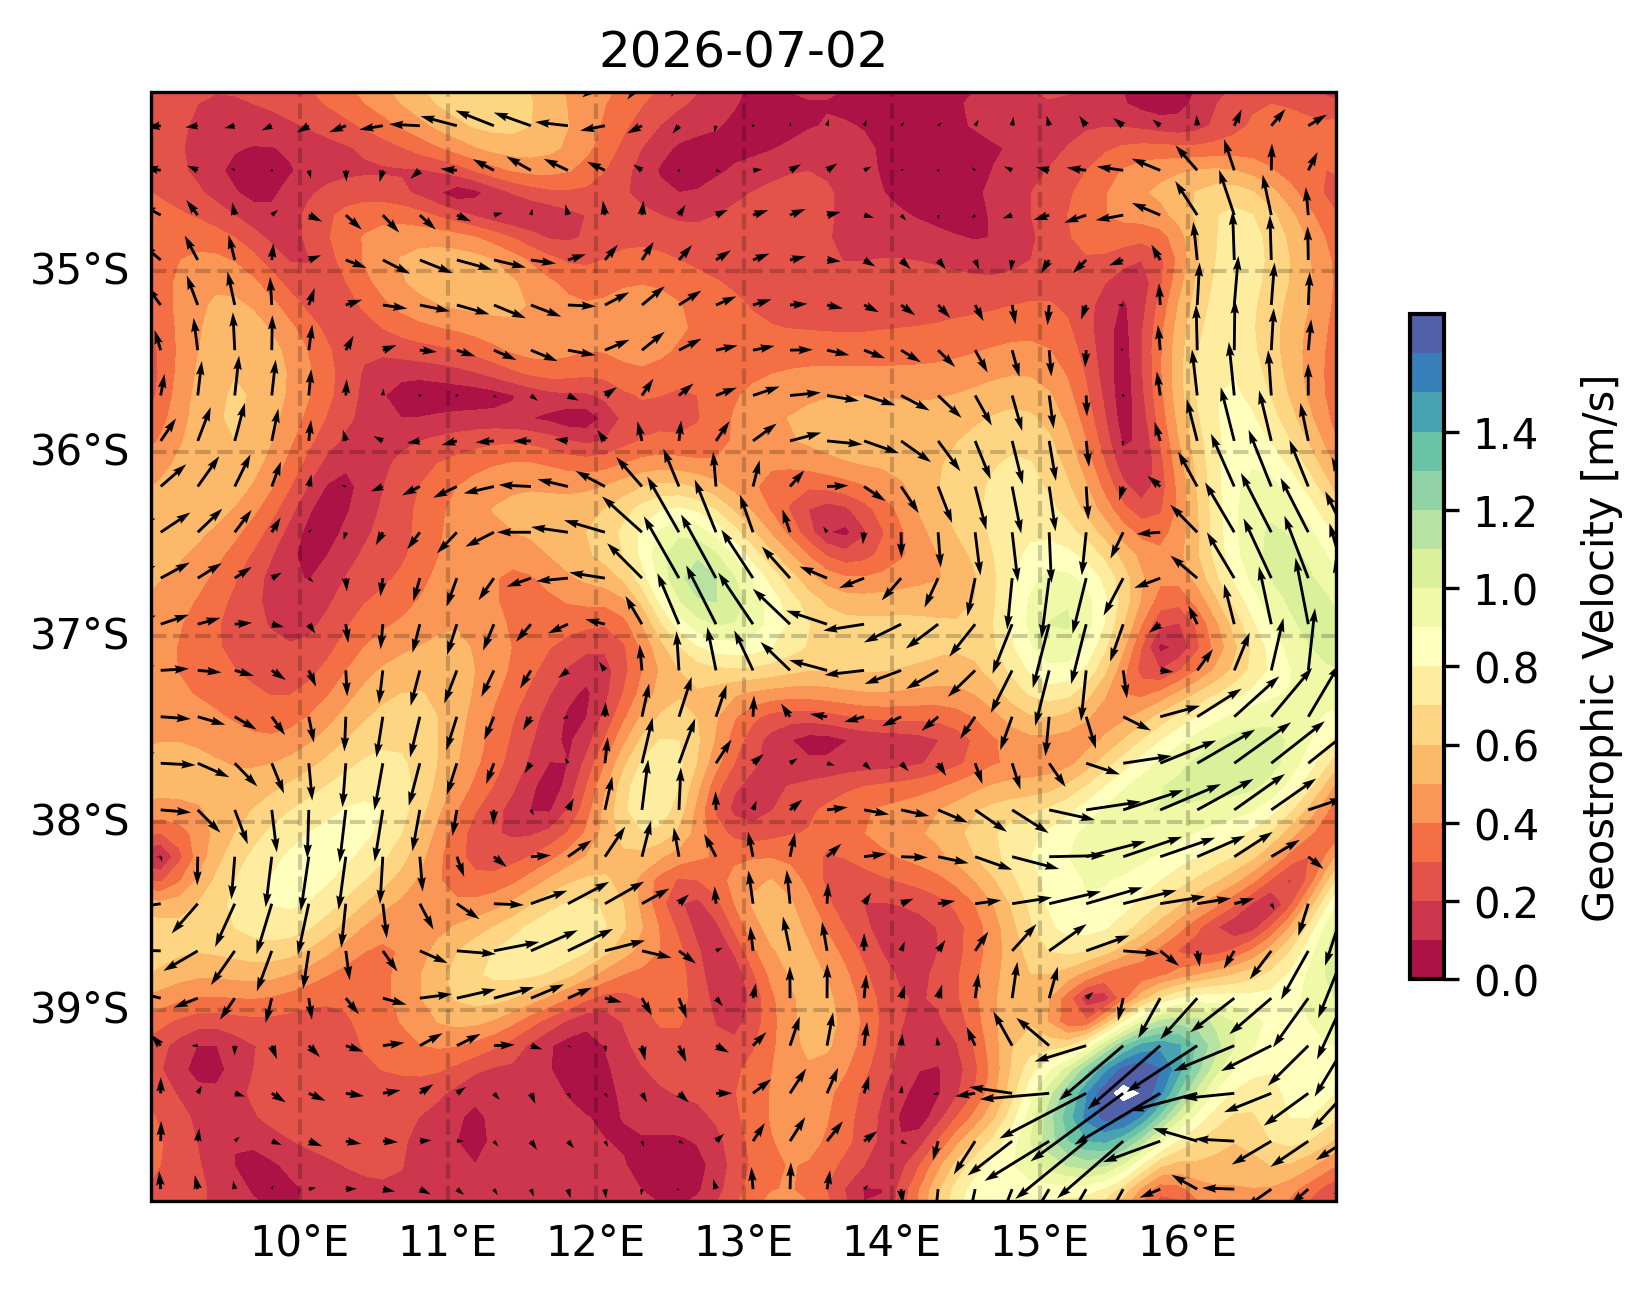

In [ ]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

fig = plt.figure(dpi=300)
ax0 = fig.add_subplot(1, 1, 1, projection=proj)

ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
               crs=ccrs.PlateCarree())
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

c2 = ax0.contourf(lons, lats, current_mag,  levels=np.arange(0, 1.8, 0.1), cmap='Spectral',
            transform=crs, linestyles='dashed', linewidths=0.7)
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(0, 1.6, 0.2))
cbar.set_label('Geostrophic Velocity [m/s]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

In [89]:
current_mag.shape

(156, 180)

In [ ]:
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="black", linestyles='solid', transform=crs, linewidths=0.8)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7)

# ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#             transform=crs, linestyles='solid', linewidths=0.7)

cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="Current Position")
ax0.scatter(s1_x, s1_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s1_x, s1_y}")
ax0.scatter(s2_x, s2_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s2_x, s2_y}")
ax0.scatter(s3_x, s3_y, s=20, color='gray', zorder=20, transform=crs, label=f"{s3_x, s3_y}")
# ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, label="MD Track", color='black', zorder=90)
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_adt_{title}.png")